[![Open in Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/aim-lab/PVBM/blob/main/rlad_pvbm_tutorial.ipynb)

# End-to-End: RLAD Segmentation and PVBM Biomarker Extraction

Segments a fundus image into arteries and veins with [RLAD-SwinV2-Large](https://huggingface.co/JonathanFhima/RLAD-SwinV2-Large), then feeds the masks into [PVBM](https://github.com/aim-lab/PVBM) to compute vasculature biomarkers and their visualizations.

**This notebook needs a GPU.** In Colab: `Runtime > Change runtime type > T4 GPU`. The model was trained in `bfloat16`, so inference below also runs in `bfloat16` to match training precision.

In [18]:
# Colab already ships torch/torchvision matched to its GPU - reinstalling them here
# risks pulling a mismatched/CPU build and can spike pip's resolver memory. Only install
# what's actually missing.
!pip install -q transformers safetensors pyyaml scikit-image opencv-python-headless pvbm huggingface_hub

## Imports

In [19]:
import gc
import numpy as np
import torch
import matplotlib.pyplot as plt
from PIL import Image
from huggingface_hub import hf_hub_download
from skimage.draw import line_aa
from skimage.morphology import skeletonize, square, dilation
from scipy.ndimage import binary_dilation

from PVBM.Datasets import PVBMDataDownloader
from PVBM.DiscSegmenter import DiscSegmenter
from PVBM.GeometryAnalysis import GeometricalVBMs
from PVBM.FractalAnalysis import MultifractalVBMs
from PVBM.CentralRetinalAnalysis import CREVBMs

# infer.py is downloaded in step 1, so it's imported there rather than here.

## 0. Check the GPU runtime

In [20]:
if torch.cuda.is_available():
    device = torch.device("cuda")
    print(f"Using GPU: {torch.cuda.get_device_name(0)}")
else:
    device = torch.device("cpu")
    print("No GPU detected - this notebook will still run, but much slower.")
    print("In Colab: Runtime > Change runtime type > T4 GPU, then re-run from the top.")

Using GPU: Tesla T4


## 1. Download the model code

In [21]:
repo = "JonathanFhima/RLAD-SwinV2-Large"
hf_hub_download(repo, "LUNetv2.py", local_dir=".")
hf_hub_download(repo, "infer.py", local_dir=".")

from infer import load_model, preprocess_image, create_vessel_mask, blend_overlay

## 2. Load the model

In [ ]:
# Config and weights download automatically (standard transformers from_pretrained).
# Loaded in bfloat16 - the precision the model was trained in.
model = load_model(repo, device)

## 3. Get an example fundus image

Downloading...
From (original): https://drive.google.com/uc?id=18TcmkuN_eZgM2Ph5XiX8x7_ejtKhA3qb
From (redirected): https://drive.google.com/uc?id=18TcmkuN_eZgM2Ph5XiX8x7_ejtKhA3qb&confirm=t&uuid=b914249d-b2da-4ffb-af69-76ca3eb60589
To: /content/INSPIRE.zip
100%|██████████| 29.6M/29.6M [00:00<00:00, 120MB/s]


Dataset downloaded and saved to INSPIRE.zip
Files extracted to PVBM_datasets
Deleted the zip file: INSPIRE.zip


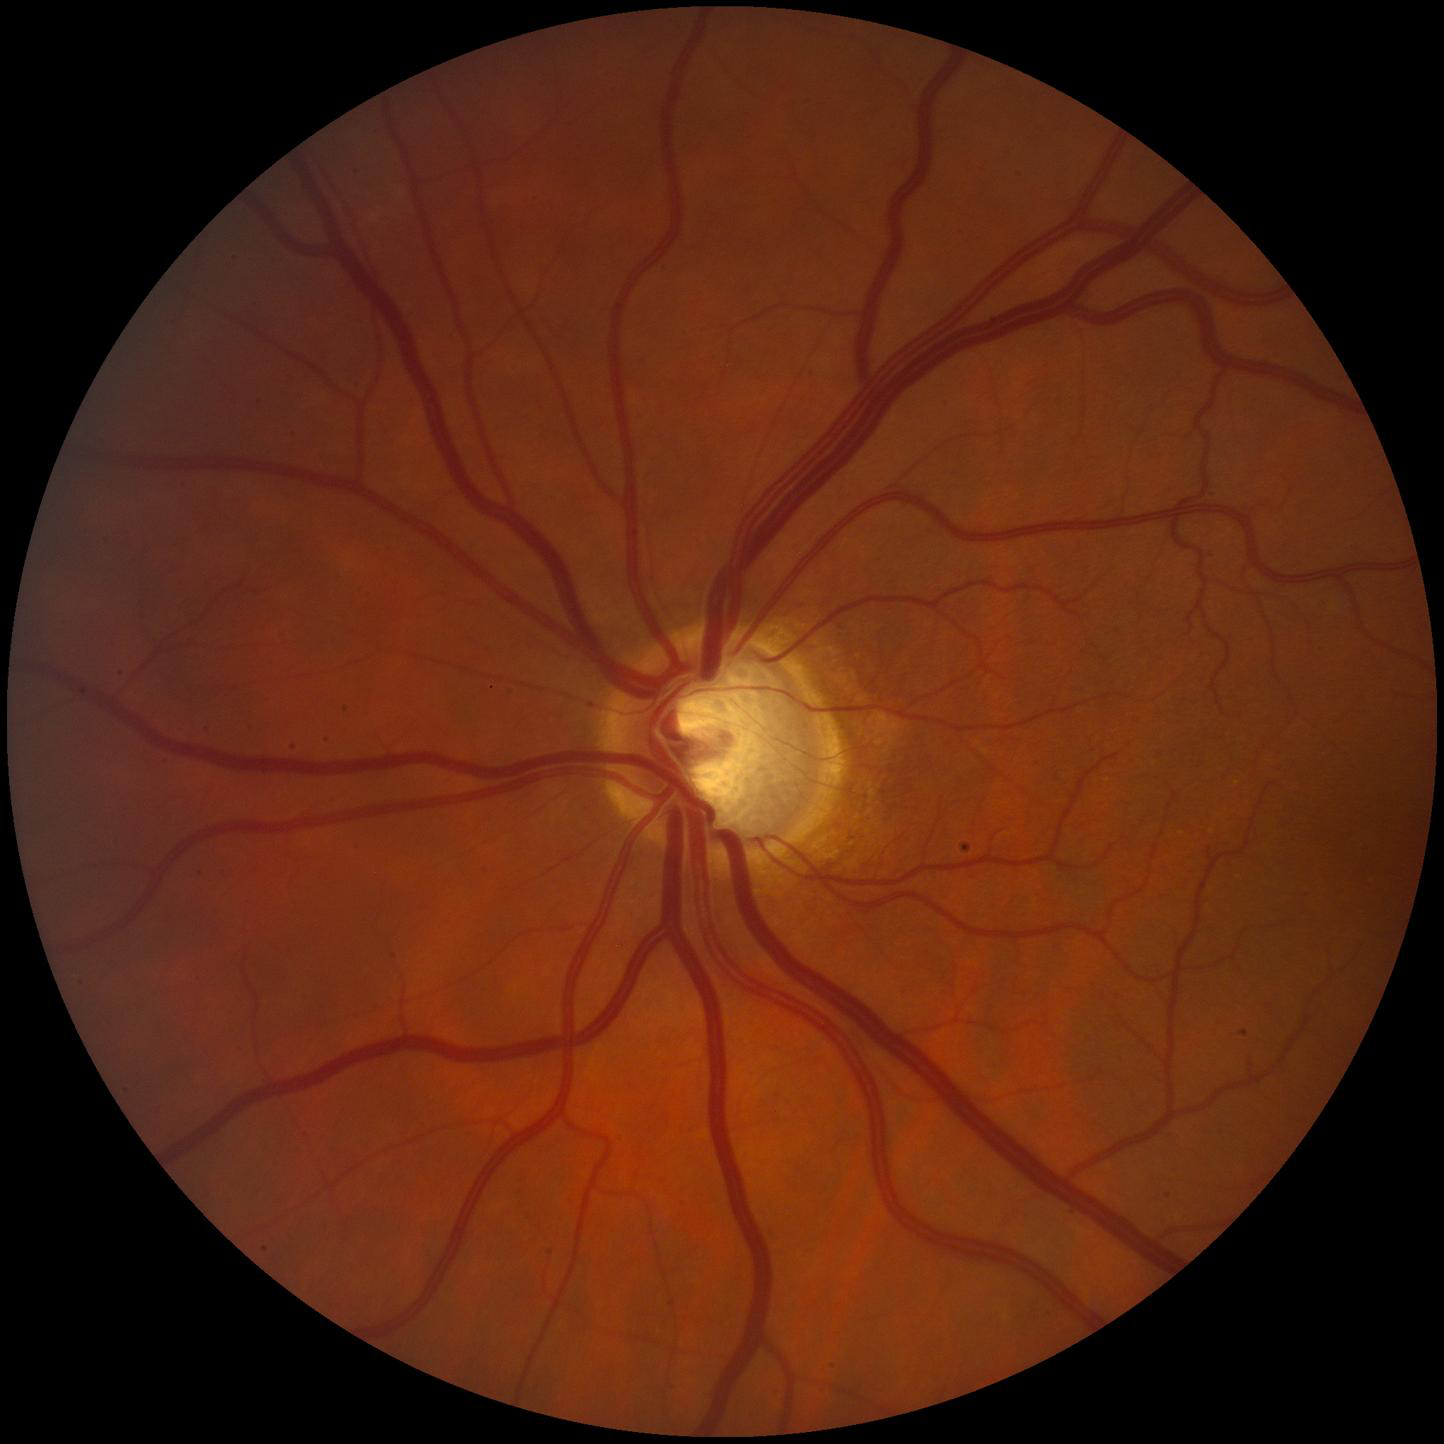

In [23]:
PVBMDataDownloader().download_dataset(name="INSPIRE", save_folder_path="PVBM_datasets")
image_path = "PVBM_datasets/INSPIRE/images/image13.png"
image = Image.open(image_path).convert("RGB")
image

## 4. Segment arteries and veins

In [24]:
with torch.no_grad():
    output = model(preprocess_image(image).to(device)).float()

probs = torch.sigmoid(output)[0].cpu().numpy()
artery = (probs[0] > 0.5).astype("uint8")
vein = (probs[1] > 0.5).astype("uint8")

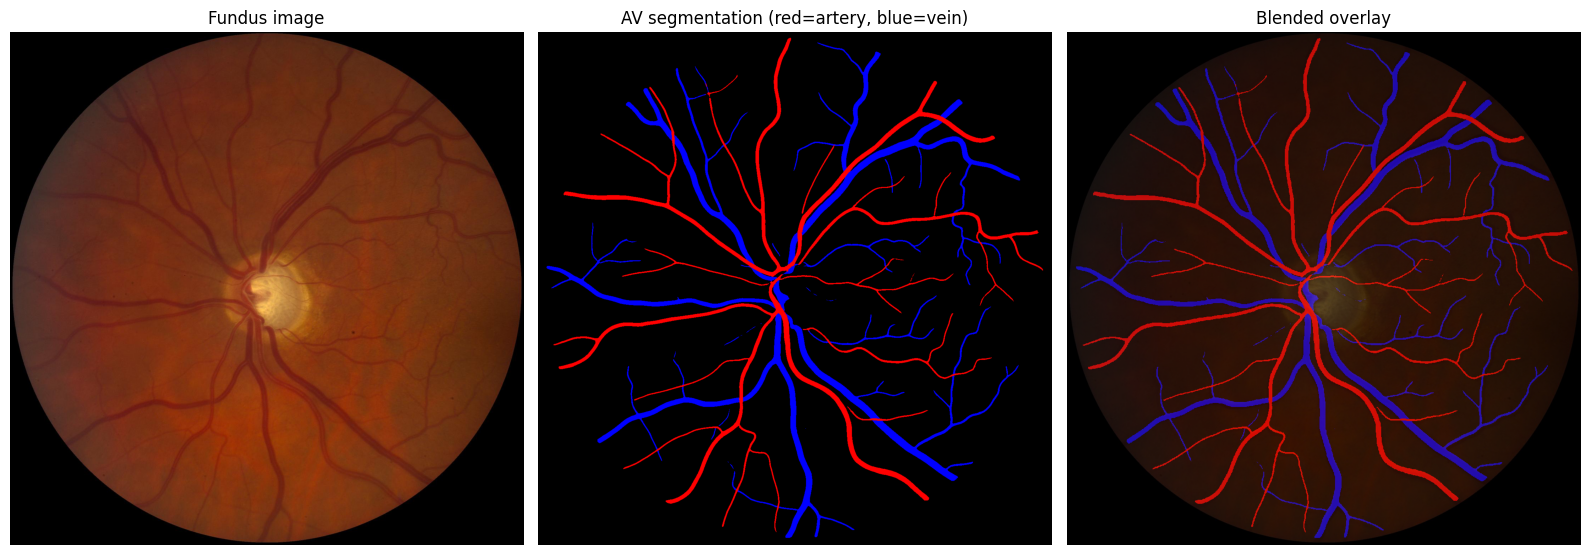

In [25]:
mask = create_vessel_mask(output)
overlay = blend_overlay(image, mask)

fig, axes = plt.subplots(1, 3, figsize=(16, 6))
axes[0].imshow(image)
axes[0].set_title("Fundus image")
axes[1].imshow(mask)
axes[1].set_title("AV segmentation (red=artery, blue=vein)")
axes[2].imshow(overlay)
axes[2].set_title("Blended overlay")
for ax in axes:
    ax.axis("off")
plt.tight_layout()
plt.show()

## 5. Skeletons

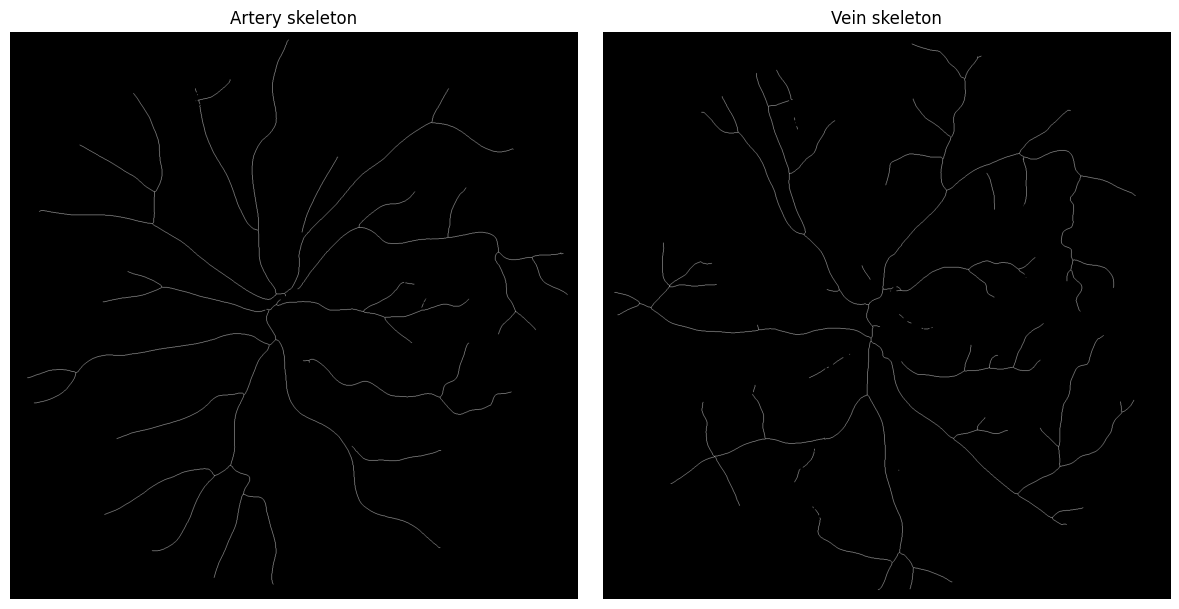

In [26]:
skeletons = {name: skeletonize(mask).astype("uint8") for name, mask in [("artery", artery), ("vein", vein)]}

fig, axes = plt.subplots(1, 2, figsize=(12, 6))
for ax, name in zip(axes, ["artery", "vein"]):
    ax.imshow(skeletons[name], cmap="gray")
    ax.set_title(f"{name.capitalize()} skeleton")
    ax.axis("off")
plt.tight_layout()
plt.show()

## 6. Optic disc localization, ROI and zones

Model path: /usr/local/lib/python3.13/dist-packages/PVBM/lunetv2_odc.onnx
Model already exists, skipping download.


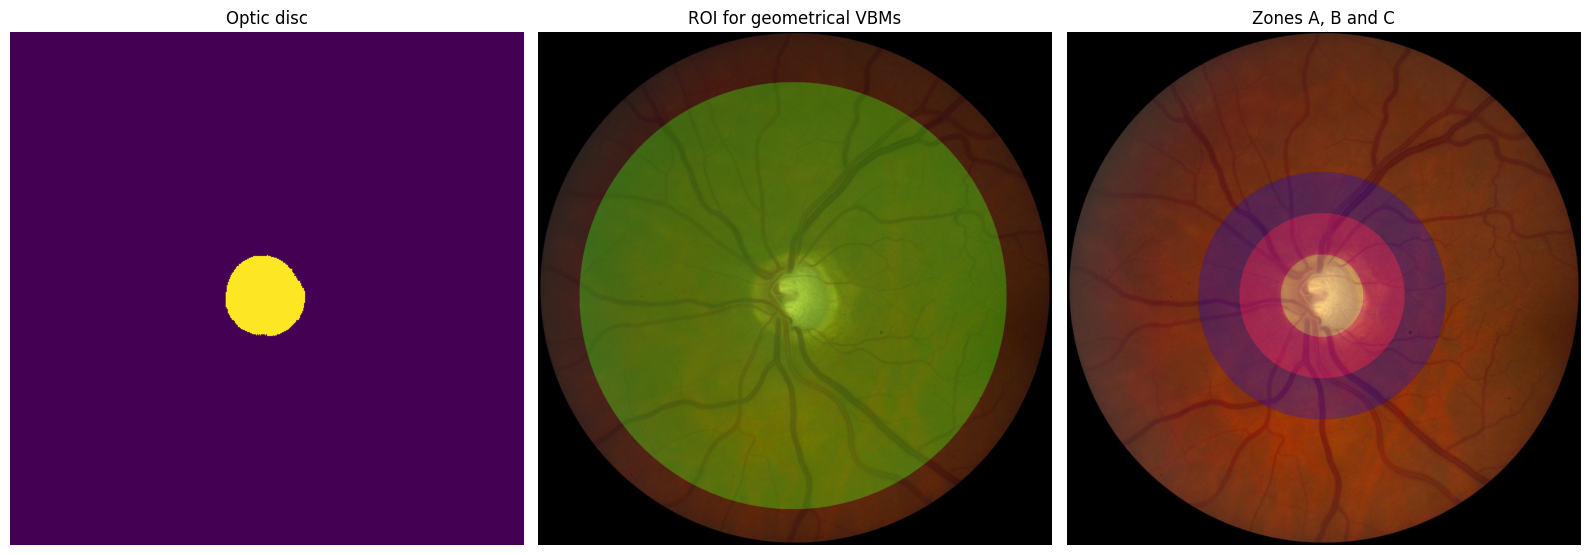

In [27]:
segmenter = DiscSegmenter()
optic_disc = segmenter.segment(image_path=image_path)
center, radius, roi, zones_ABC = segmenter.post_processing(segmentation=optic_disc, max_roi_size=600)

fig, axes = plt.subplots(1, 3, figsize=(16, 6))
axes[0].imshow(optic_disc)
axes[0].set_title("Optic disc")
axes[1].imshow(image)
axes[1].imshow(roi, alpha=0.3)
axes[1].set_title("ROI for geometrical VBMs")
axes[2].imshow(image)
axes[2].imshow(zones_ABC / 255, alpha=0.5)
axes[2].set_title("Zones A, B and C")
for ax in axes:
    ax.axis("off")
plt.tight_layout()
plt.show()

## 7. Vasculature biomarkers

In [28]:
geometricalVBMs = GeometricalVBMs()
fractalVBMs = MultifractalVBMs(n_rotations=25, optimize=True, min_proba=0.0001, maxproba=0.9999)
creVBMs = CREVBMs()

results = {}
viz = {}

for name, segmentation in [("artery", artery), ("vein", vein)]:
    print(f"=== {name} ===")
    skeleton = skeletons[name]

    seg_roi, skel_roi = geometricalVBMs.apply_roi(segmentation=segmentation, skeleton=skeleton, zones_ABC=zones_ABC, roi=roi)
    vbms, geom_viz = geometricalVBMs.compute_geomVBMs(blood_vessel=seg_roi, skeleton=skel_roi, xc=center[0], yc=center[1], radius=radius)
    area, TI, medTor, ovlen, medianba, startp, endp, interp = vbms
    endpoints, interpoints, startpoints, angles_dico, topology_dico = geom_viz
    print(f"Area: {area} \nTortuosity Index: {TI} \nMedian Tortuosity: {medTor}\nOverall Length: {ovlen}"
          f"\nMedian Branching angle: {medianba}\nNumber of Start/End/Intersection points: {startp}/{endp}/{interp}")

    D0, D1, D2, SL = fractalVBMs.compute_multifractals(seg_roi.copy())
    print(f"Fractal biomarkers: D0={D0}, D1={D1}, D2={D2}, SL={SL}")

    cre_seg_roi, cre_skel_roi = creVBMs.apply_roi(segmentation=segmentation, skeleton=skeleton, zones_ABC=zones_ABC)
    cre, cre_visual = creVBMs.compute_central_retinal_equivalents(
        blood_vessel=cre_seg_roi.copy(), skeleton=cre_skel_roi.copy(),
        xc=center[0], yc=center[1], radius=radius, artery=(name == "artery"), Toplot=False,
    )
    print(f"CRE: {cre}")

    cre_startpoints = np.zeros(cre_seg_roi.shape[:2], dtype="uint8")
    cre_annotations = []
    for item in cre_visual:
        cre_startpoints[item["start"]] = 1
        cre_annotations.append((item["end"], item["Median diameter"]))
    del cre_visual
    gc.collect()

    results[name] = dict(
        area=area, tortuosity_index=TI, median_tortuosity=medTor, length=ovlen,
        median_branching_angle=medianba, startpoints=startp, endpoints=endp, intersections=interp,
        capacity_dimension=D0, entropy_dimension=D1, correlation_dimension=D2, singularity_length=SL,
        cre_knudtson=cre["craek" if name == "artery" else "crvek"],
        cre_hubbard=cre["craeh" if name == "artery" else "crveh"],
    )
    viz[name] = dict(
        segmentation=segmentation, seg_roi=seg_roi.astype("uint8"), skel_roi=skel_roi.astype("uint8"),
        endpoints=endpoints.astype("uint8"), interpoints=interpoints.astype("uint8"), startpoints=startpoints.astype("uint8"),
        angles_dico=angles_dico, topology_dico=topology_dico,
        cre_seg_roi=cre_seg_roi.astype("uint8"),
        cre_startpoints=cre_startpoints, cre_annotations=cre_annotations,
    )
    del seg_roi, skel_roi, cre_seg_roi, cre_skel_roi
    gc.collect()

results["avr_knudtson"] = results["artery"]["cre_knudtson"] / results["vein"]["cre_knudtson"]
results["avr_hubbard"] = results["artery"]["cre_hubbard"] / results["vein"]["cre_hubbard"]
results

=== artery ===
Area: 61419.0 
Tortuosity Index: 1.1073322456969523 
Median Tortuosity: 1.0887639377962377
Overall Length: 8137.690326906352
Median Branching angle: 72.68436448999617
Number of Start/End/Intersection points: 10/26.0/16.0
Fractal biomarkers: D0=1.3677138347159032, D1=1.3390781840439399, D2=1.3202114036232115, SL=0.8681553445461221
CRE: {'craek': np.float64(18.893130784439613), 'craeh': np.float64(20.167523575847095)}
=== vein ===
Area: 74710.0 
Tortuosity Index: 1.1101577010945445 
Median Tortuosity: 1.0905433006757965
Overall Length: 7217.764353311043
Median Branching angle: 73.98534130697152
Number of Start/End/Intersection points: 7/31.0/25.0
Fractal biomarkers: D0=1.3694035221093046, D1=1.314793611040705, D2=1.2909755026512735, SL=0.9628253027205977
CRE: {'crvek': np.float64(33.07330652648127), 'crveh': np.float64(52.335502333890076)}


{'artery': {'area': np.float64(61419.0),
  'tortuosity_index': np.float64(1.1073322456969523),
  'median_tortuosity': np.float64(1.0887639377962377),
  'length': np.float64(8137.690326906352),
  'median_branching_angle': np.float64(72.68436448999617),
  'startpoints': 10,
  'endpoints': np.float64(26.0),
  'intersections': np.float64(16.0),
  'capacity_dimension': np.float64(1.3677138347159032),
  'entropy_dimension': np.float64(1.3390781840439399),
  'correlation_dimension': np.float64(1.3202114036232115),
  'singularity_length': np.float64(0.8681553445461221),
  'cre_knudtson': np.float64(18.893130784439613),
  'cre_hubbard': np.float64(20.167523575847095)},
 'vein': {'area': np.float64(74710.0),
  'tortuosity_index': np.float64(1.1101577010945445),
  'median_tortuosity': np.float64(1.0905433006757965),
  'length': np.float64(7217.764353311043),
  'median_branching_angle': np.float64(73.98534130697152),
  'startpoints': 7,
  'endpoints': np.float64(31.0),
  'intersections': np.float6

## 8. Visualizations

In [29]:
def show_pair(title, plot_fn, figsize=(12, 6)):
    fig, axes = plt.subplots(1, 2, figsize=figsize)
    for ax, name in zip(axes, ["artery", "vein"]):
        plot_fn(ax, name)
        ax.set_title(f"{name.capitalize()}: {title}")
        ax.axis("off")
    plt.tight_layout()
    plt.show()

### ROI segmentation and skeleton

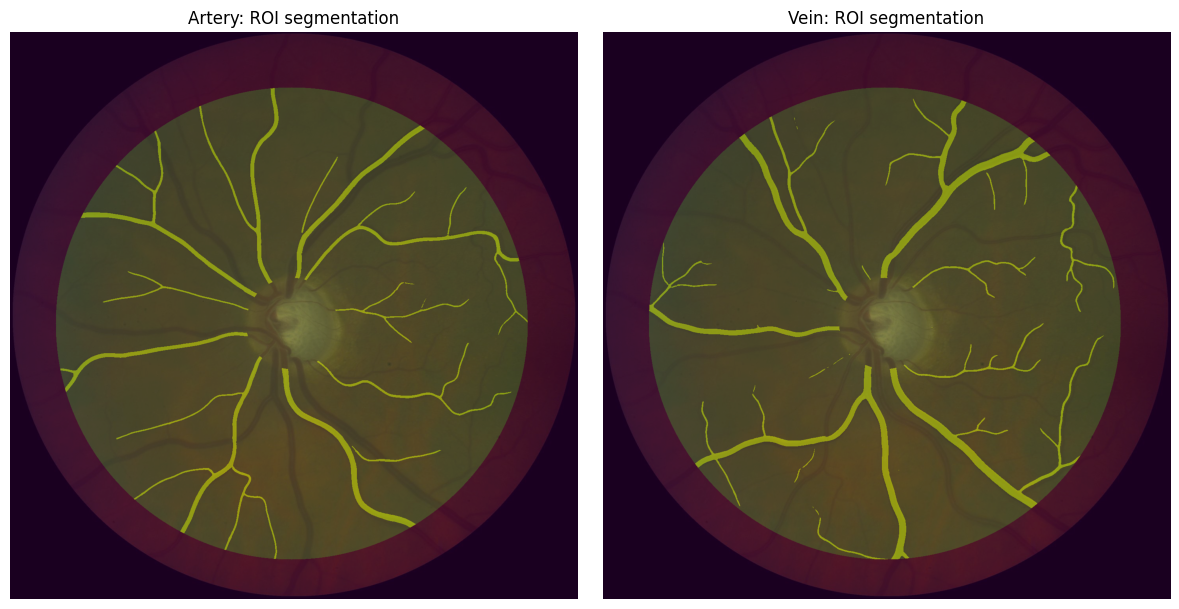

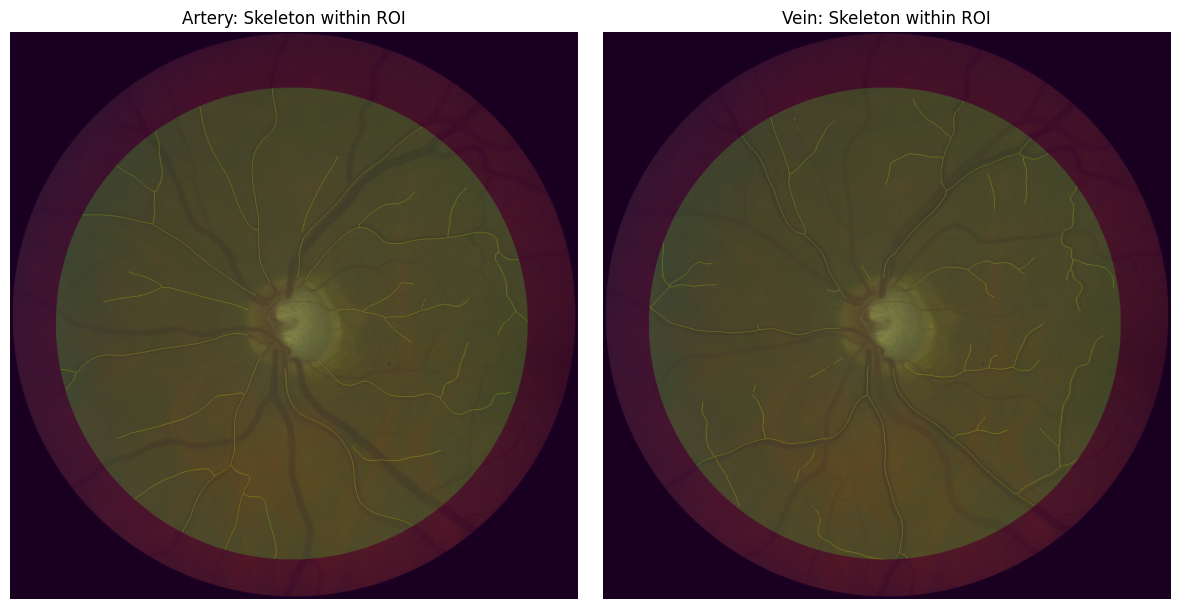

In [30]:
show_pair("ROI segmentation", lambda ax, name: (
    ax.imshow(image), ax.imshow(viz[name]["seg_roi"], alpha=0.5), ax.imshow(roi, alpha=0.2),
))
show_pair("Skeleton within ROI", lambda ax, name: (
    ax.imshow(image), ax.imshow(viz[name]["skel_roi"], alpha=0.5), ax.imshow(roi, alpha=0.2),
))

### Branching angles

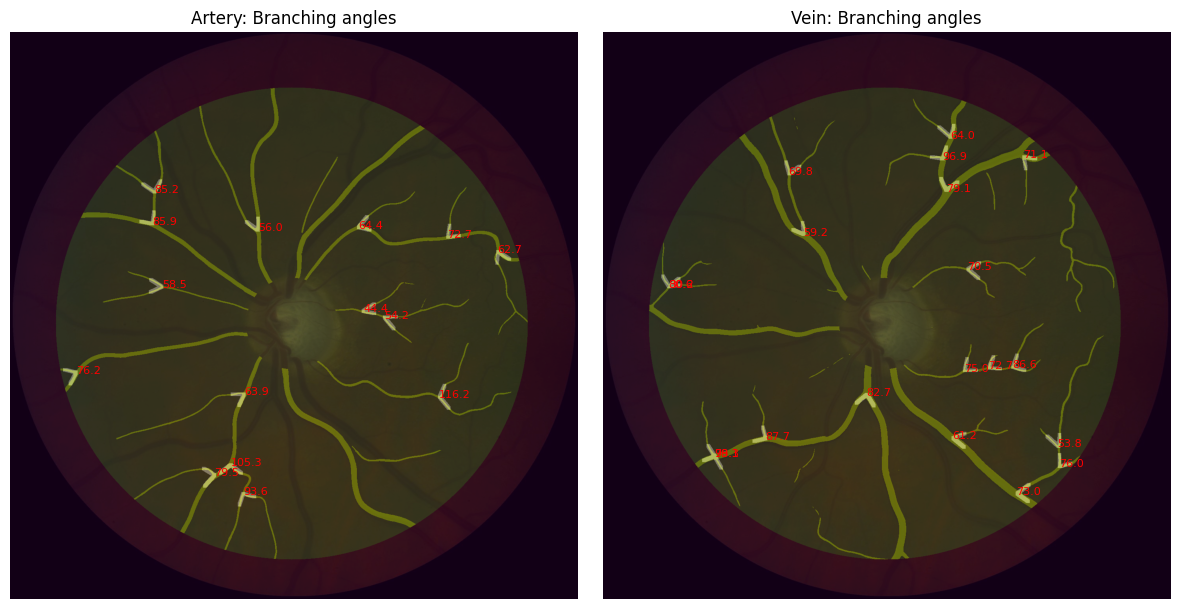

In [31]:
def draw_angles(ax, name):
    data = viz[name]
    img = np.zeros_like(data["segmentation"], dtype="float64")
    for b, value in data["angles_dico"].items():
        if len(value) == 2:
            a, c = value
            pairs = [(a, b, c)]
        elif len(value) == 3:
            a, c, d = value
            pairs = [(a, b, c), (c, b, d)]
        else:
            pairs = []
        for p1, vertex, p2 in pairs:
            if all(x is not None for x in (p1, vertex, p2)):
                v1 = np.array(p1) - np.array(vertex)
                v2 = np.array(p2) - np.array(vertex)
                cosine = np.dot(v1, v2) / (np.linalg.norm(v1) * np.linalg.norm(v2))
                angle = np.degrees(np.arccos(np.clip(cosine, -1, 1)))
                rr, cc, val = line_aa(vertex[0], vertex[1], p1[0], p1[1])
                img[rr, cc] = val * 255
                rr, cc, val = line_aa(vertex[0], vertex[1], p2[0], p2[1])
                img[rr, cc] = val * 255
                ax.text(vertex[1], vertex[0], f"{angle:.1f}", color="red", fontsize=8)
    img_dilated = binary_dilation(img, structure=np.ones((8, 8))) * 255
    ax.imshow(image)
    ax.imshow(data["seg_roi"], alpha=0.5)
    ax.imshow(roi, alpha=0.2)
    ax.imshow(img_dilated, cmap="gray", alpha=0.3)


show_pair("Branching angles", draw_angles)

### Particular points

/tmp/ipykernel_1871/2959745004.py:3: FutureWarning: `square` is deprecated since version 0.25 and will be removed in version 0.27. Use `skimage.morphology.footprint_rectangle` instead.
  ax.imshow(viz[name]["segmentation"] / 50 + dilation(viz[name]["endpoints"], square(15)), alpha=0.5),


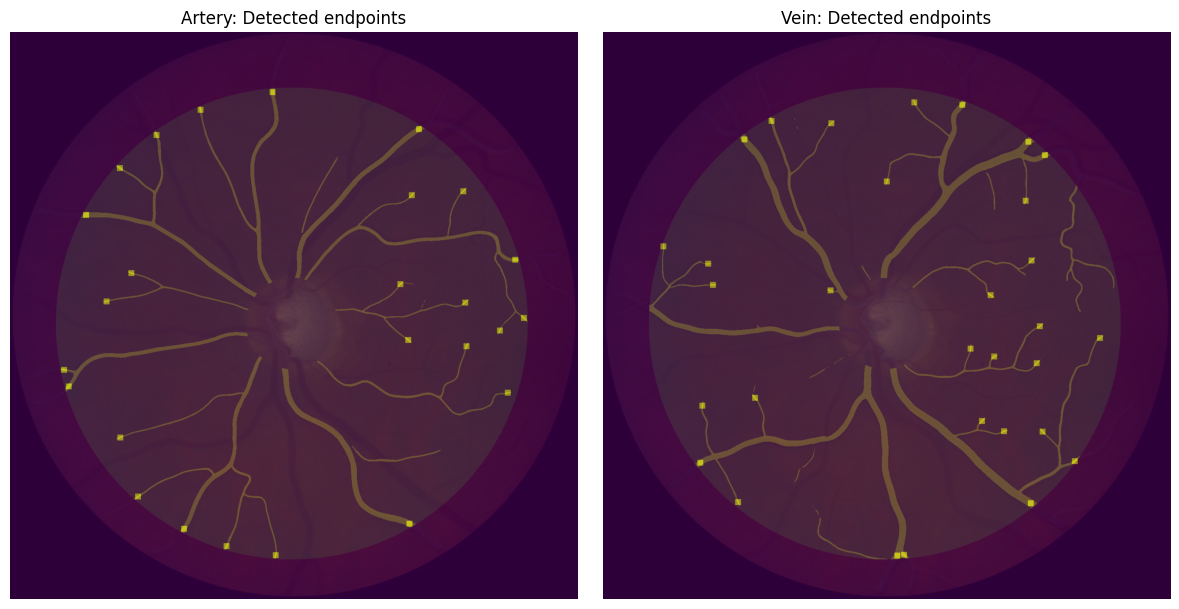

/tmp/ipykernel_1871/2959745004.py:7: FutureWarning: `square` is deprecated since version 0.25 and will be removed in version 0.27. Use `skimage.morphology.footprint_rectangle` instead.
  ax.imshow(viz[name]["segmentation"] / 20 + dilation(viz[name]["interpoints"], square(15)), alpha=0.5),


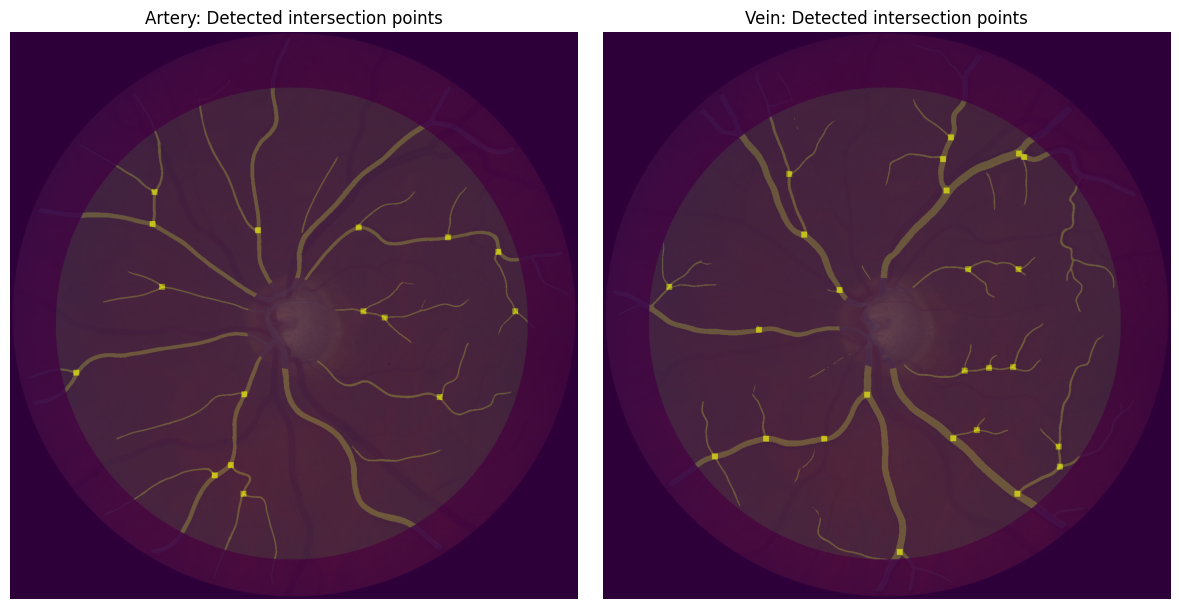

/tmp/ipykernel_1871/2959745004.py:11: FutureWarning: `square` is deprecated since version 0.25 and will be removed in version 0.27. Use `skimage.morphology.footprint_rectangle` instead.
  ax.imshow(viz[name]["segmentation"] / 20 + dilation(viz[name]["startpoints"], square(15)), alpha=0.5),


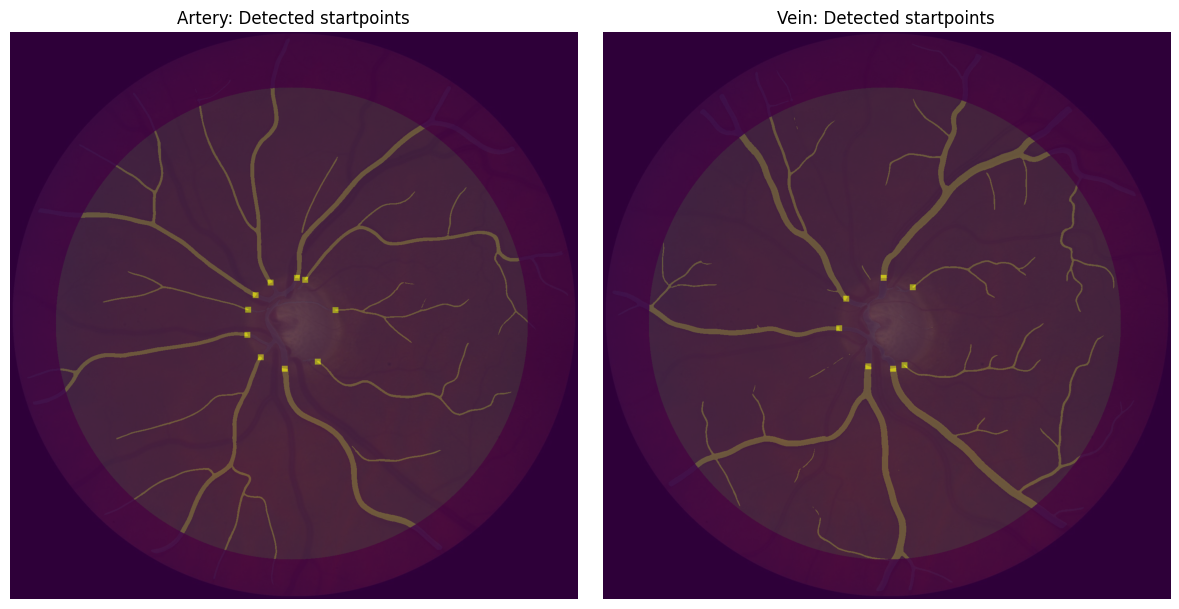

In [32]:
show_pair("Detected endpoints", lambda ax, name: (
    ax.imshow(image), ax.imshow(viz[name]["seg_roi"], alpha=0.5), ax.imshow(roi, alpha=0.2),
    ax.imshow(viz[name]["segmentation"] / 50 + dilation(viz[name]["endpoints"], square(15)), alpha=0.5),
))
show_pair("Detected intersection points", lambda ax, name: (
    ax.imshow(image), ax.imshow(viz[name]["seg_roi"], alpha=0.5), ax.imshow(roi, alpha=0.2),
    ax.imshow(viz[name]["segmentation"] / 20 + dilation(viz[name]["interpoints"], square(15)), alpha=0.5),
))
show_pair("Detected startpoints", lambda ax, name: (
    ax.imshow(image), ax.imshow(viz[name]["seg_roi"], alpha=0.5), ax.imshow(roi, alpha=0.2),
    ax.imshow(viz[name]["segmentation"] / 20 + dilation(viz[name]["startpoints"], square(15)), alpha=0.5),
))

### Tortuosity (linear interpolation of the particular points)

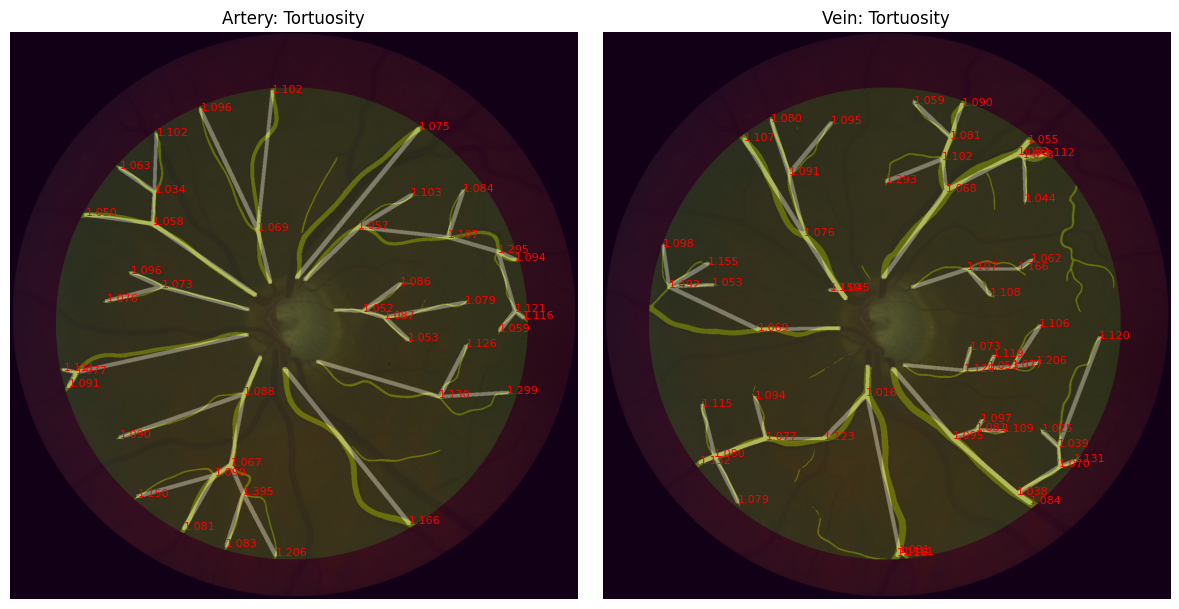

In [33]:
def draw_topology(ax, name):
    data = viz[name]
    img = np.zeros_like(data["segmentation"], dtype="float64")
    for key, value in data["topology_dico"].items():
        rr, cc, val = line_aa(key[0], key[1], key[2], key[3])
        img[rr, cc] = val * 255
        ax.text(key[3], key[2], f"{value[0] / value[1]:.3f}", color="red", fontsize=8)
    img_dilated = binary_dilation(img, structure=np.ones((8, 8))) * 255
    ax.imshow(image)
    ax.imshow(data["seg_roi"], alpha=0.5)
    ax.imshow(roi, alpha=0.2)
    ax.imshow(img_dilated, cmap="gray", alpha=0.3)


show_pair("Tortuosity", draw_topology)

### Central Retinal Equivalent (CRE)

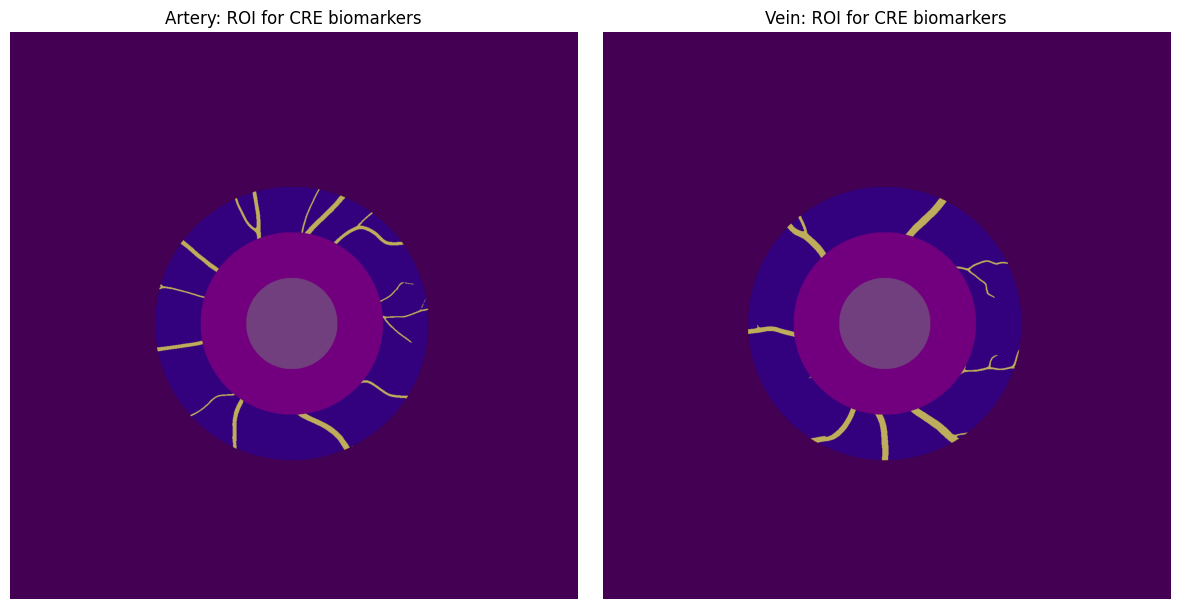

/tmp/ipykernel_1871/2183519237.py:12: FutureWarning: `square` is deprecated since version 0.25 and will be removed in version 0.27. Use `skimage.morphology.footprint_rectangle` instead.
  ax.imshow(dilation(data["cre_startpoints"], square(15)), alpha=0.5)


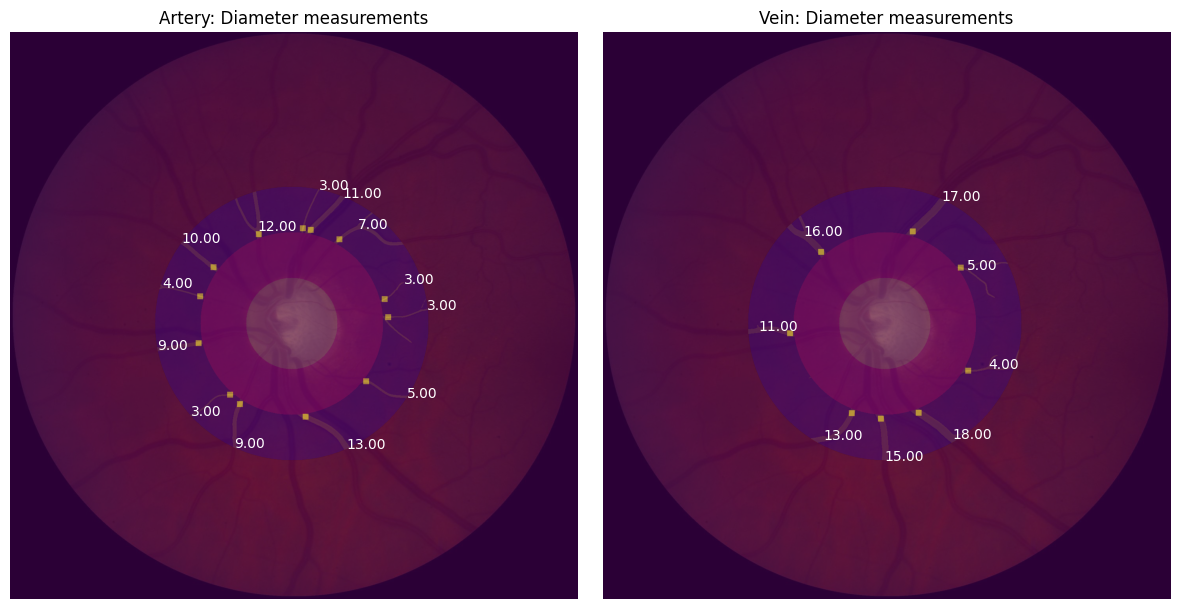

In [34]:
show_pair("ROI for CRE biomarkers", lambda ax, name: (
    ax.imshow(viz[name]["cre_seg_roi"]), ax.imshow(zones_ABC / 255, alpha=0.5),
))

def draw_cre_diameters(ax, name):
    data = viz[name]
    ax.imshow(image)
    ax.imshow(data["cre_seg_roi"], alpha=0.3)
    ax.imshow(zones_ABC / 255, alpha=0.5)
    for end_location, median_diameter in data["cre_annotations"]:
        ax.annotate(f"{median_diameter:.2f}", (end_location[1], end_location[0]), color="white", fontsize=10)
    ax.imshow(dilation(data["cre_startpoints"], square(15)), alpha=0.5)


show_pair("Diameter measurements", draw_cre_diameters)